# Sanskrit → English Machine Translation with a Transformer, mT5, LLaMA and Gemma
**Dataset:** Itihasa – 93,000 Sanskrit–English shloka pairs from the Rāmāyaṇa and the Mahābhārata (Aralikatte et al., 2021) – https://huggingface.co/datasets/rahular/itihasa

On Kaggle:
1. Settings → Accelerator → **GPU T4 x2** (or P100), and turn **Internet on**.
2. Use **Save Version → Save & Run All (Commit)** so the run continues in the background even if the browser tab closes (about 45 min on a T4). No Hugging Face token is needed. All results are written to `results/` and `samples/`, and zipped into `ia3_outputs.zip` at the end.

In [3]:
!pip install -q "transformers>=4.50" peft sacrebleu sentencepiece

In [4]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less GPU memory fragmentation
import re, gc, time, math, random, shutil, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import sacrebleu
import sentencepiece as spm
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
                          get_linear_schedule_with_warmup)
from peft import LoraConfig, get_peft_model

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

N_TRAIN, N_VAL, N_TEST = 20000, 1000, 300   # subset sizes
N_LLM_TRAIN = 1000                           # pairs used for LoRA fine-tuning of LLaMA and Gemma
N_TEMP = 50                                  # test sentences used for the temperature analysis
TEMPERATURES = [0.5, 1.0, 1.5]
MAX_NEW_TOKENS = 96                          # same generation limit for every model
INFER_BS = 16                                # same inference batch size for every model

os.makedirs("results/plots", exist_ok=True)
os.makedirs("samples", exist_ok=True)

Device: cuda Tesla T4


## 1. Dataset
Itihasa is stored on Hugging Face as plain text files with one verse per line (`*.sn.csv` for Sanskrit, `*.en.csv` for English). Line *i* of the Sanskrit file is the translation pair of line *i* of the English file. The English side is M. N. Dutt's 19th-century translation.

In [5]:
BASE = "https://huggingface.co/datasets/rahular/itihasa/resolve/main/"

def read_split(name):
    sa = urllib.request.urlopen(BASE + f"{name}.sn.csv").read().decode("utf-8").split("\n")
    en = urllib.request.urlopen(BASE + f"{name}.en.csv").read().decode("utf-8").split("\n")
    assert len(sa) == len(en), (name, len(sa), len(en))
    return pd.DataFrame({"sa": sa, "en": en})

raw = {split: read_split(split) for split in ["train", "dev", "test"]}
for split, df in raw.items():
    print(f"{split:5s}: {len(df):,} pairs")

pd.set_option("display.max_colwidth", 200)
raw["train"].sample(3, random_state=SEED)

train: 75,162 pairs
dev  : 6,149 pairs
test : 11,722 pairs


,sa,en
38895,चक्रे वायुः पृष्ठतः पाण्डवानां धार्तराष्ट्राश्वापदा व्यारहन्त। गजेन्द्राणां मदग्न्धांश्च तीव्रान् न सेहिरे तव पुत्रस्य नागाः॥,"The wind blew from behind the Pandavas. The beasts of prey yelled, from behind the troops of your sons. The elephants, belonging to your son, could not bear the strong odour of the juice emitted b..."
29344,एतासां वीर्यसम्पन्नः शिशु मातिदारुणः। स्कन्दप्रसादजः पुत्रो लोहिताक्षो भयंकरः॥,"They had a powerful, red-eyed, terrific and very turbulent son, named Shishu, born by the blessings of Skanda."
62163,अविद्या कर्म तृष्णा च केचिदाहुः पुनर्भवे। कारणं लोभमोहौ तु दोषाणां तु निषेवणम्॥,"Some hold that there is re-birth which is caused by Ignorance, the desire for acts, cupidity, carelessness, and bent towards other vices."


In [6]:
def describe(df, name):
    sa_words, en_words = df.sa.str.split().str.len(), df.en.str.split().str.len()
    return {"split": name, "pairs": len(df),
            "sa words (mean)": round(sa_words.mean(), 1), "sa words (median)": sa_words.median(),
            "en words (mean)": round(en_words.mean(), 1), "en words (median)": en_words.median(),
            "sa vocabulary": len(set(" ".join(df.sa).split())),
            "en vocabulary": len(set(" ".join(df.en).lower().split()))}

raw_stats = pd.DataFrame([describe(df, s) for s, df in raw.items()])
raw_stats

,split,pairs,sa words (mean),sa words (median),en words (mean),en words (median),sa vocabulary,en vocabulary
0,train,75162,11.2,10.0,31.1,27.0,267523,76394
1,dev,6149,11.6,10.0,31.9,27.0,36193,19194
2,test,11722,11.2,10.0,30.7,27.0,60526,27749


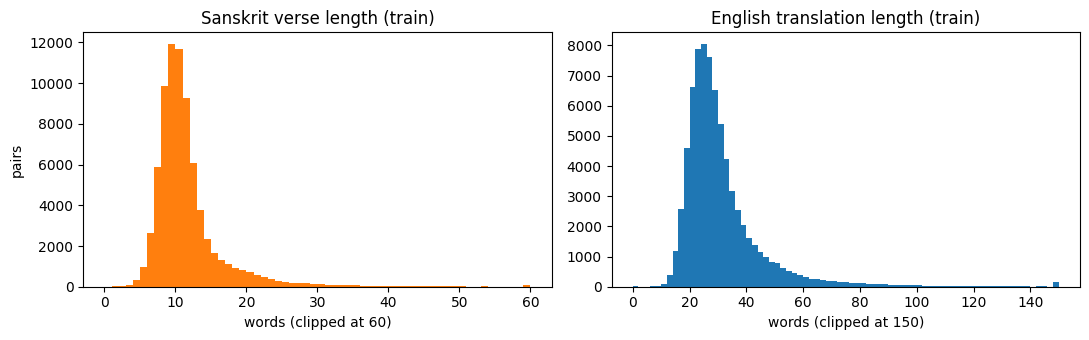

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(raw["train"].sa.str.split().str.len().clip(upper=60), bins=60, color="tab:orange")
axes[0].set(title="Sanskrit verse length (train)", xlabel="words (clipped at 60)", ylabel="pairs")
axes[1].hist(raw["train"].en.str.split().str.len().clip(upper=150), bins=75, color="tab:blue")
axes[1].set(title="English translation length (train)", xlabel="words (clipped at 150)")
plt.tight_layout(); plt.savefig("results/plots/length_distribution.png", dpi=150); plt.show()

## 2. Preprocessing and train / validation / test split
1. Unicode NFC normalisation (Devanagari vowel signs can be stored in more than one way), curly quotes → straight quotes, collapse whitespace.
2. Drop empty lines and exact duplicate pairs.
3. Keep verses with ≤ 20 Sanskrit words and ≤ 50 English words (about 90% of the data). This keeps training and LLM inference affordable on one T4.
4. Drop likely misaligned pairs: the English/Sanskrit word ratio must be between 1 and 8 (the median ratio is about 2.7).
5. Remove from the training pool any verse whose Sanskrit text also appears in the test or validation pool (no leakage).
6. Sample a manageable subset with a fixed seed: **20,000 train** (from the official train split), **1,000 validation** (from dev) and **300 test** (from test). All four models use exactly the same subsets.

In [8]:
def clean(text):
    text = unicodedata.normalize("NFC", text)
    text = text.replace("“", '"').replace("”", '"').replace("‘", "'").replace("’", "'")
    return re.sub(r"\s+", " ", text).strip()

def preprocess(df):
    df = df.assign(sa=df.sa.map(clean), en=df.en.map(clean))
    df = df[(df.sa != "") & (df.en != "")].drop_duplicates()
    sa_len, en_len = df.sa.str.split().str.len(), df.en.str.split().str.len()
    ratio = en_len / sa_len
    return df[(sa_len <= 20) & (en_len <= 50) & (ratio >= 1) & (ratio <= 8)].reset_index(drop=True)

clean_splits = {s: preprocess(df) for s, df in raw.items()}
held_out = set(clean_splits["dev"].sa) | set(clean_splits["test"].sa)
clean_splits["train"] = clean_splits["train"][~clean_splits["train"].sa.isin(held_out)]

train = clean_splits["train"].sample(N_TRAIN, random_state=SEED).reset_index(drop=True)
val   = clean_splits["dev"].sample(N_VAL, random_state=SEED).reset_index(drop=True)
test  = clean_splits["test"].sample(N_TEST, random_state=SEED).reset_index(drop=True)

filter_table = pd.DataFrame({
    "raw pairs": {s: len(raw[s]) for s in raw},
    "after cleaning + filtering": {s: len(clean_splits[s]) for s in raw},
    "used (subset)": {"train": len(train), "dev": len(val), "test": len(test)}})
print(filter_table)

dataset_stats = pd.DataFrame([describe(train, "train"), describe(val, "validation"), describe(test, "test")])
dataset_stats.to_csv("results/dataset_stats.csv", index=False)
filter_table.to_csv("results/dataset_filtering.csv")
dataset_stats

       raw pairs  after cleaning + filtering  used (subset)
train      75162                       67922          20000
dev         6149                        5531           1000
test       11722                       10678            300


,split,pairs,sa words (mean),sa words (median),en words (mean),en words (median),sa vocabulary,en vocabulary
0,train,20000,10.1,10.0,27.4,26.0,85223,33888
1,validation,1000,10.3,10.0,27.9,26.0,7014,6043
2,test,300,10.1,10.0,27.5,26.0,2423,2805


In [9]:
src_test, ref_test = test.sa.tolist(), test.en.tolist()
for i in range(3):
    print("SA :", src_test[i]); print("EN :", ref_test[i]); print()

SA : सुफलचित्रकोशश्च हेमत्सरुरनुत्तमः। निस्त्रिंशः कौरवस्यैष धर्मराजस्य धीमतः॥
EN : This most excellent sword, of a sharp blade, golden hilt and cased in a painted sheath, belongs to the intelligent Dharmaraja of the Kuru race.

SA : तत: संख्यातुमारब्धमदशद् दशमे पदे। तस्य दष्टस्य तद् रूपं क्षिप्रमन्तरधीयत॥
EN : Thereupon the king commenced counting his own steps, and at the tenth step he was bit. Having thus bitten him, the snake soon assumed a speedy change, viz., his original form.

SA : एतदिच्छाम्यहं श्रोतुं पिण्डेषु त्रिषु श गतिः॥ फलं वृत्तिं च मार्गं च यश्चैनं प्रतिपद्यते।
EN : I wish to hear this, that is, what are the ends attained by the balls offered at Shraddhas when thus disposed of by being thrown into the waters, given to the wife, and thrown into the burning fire.



## 3. Shared evaluation helpers
Every system is evaluated in the same way:
- **BLEU** and **chrF** with `sacrebleu` (corpus level, against the single reference translation). chrF works on character n-grams, so it gives partial credit for near-miss word forms and is more reliable than BLEU on a small test set.
- **Training / fine-tuning time**, **inference time** for the 300 test verses (greedy decoding, batch size 16, at most 96 new tokens), **number of parameters** (total and trainable), and **peak GPU memory**.
- **Temperature analysis**: the first 50 test verses are translated again by sampling at T = 0.5, 1.0 and 1.5 (pure temperature sampling, no top-k / top-p), and we measure BLEU, chrF, output diversity (distinct-1/2) and output length.

In [10]:
results, train_logs, temp_rows, temp_samples = [], [], [], []
translations = test[["sa", "en"]].copy()
raw_llm_outputs = {}

def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

def sync():
    if device == "cuda": torch.cuda.synchronize()

def reset_memory():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def peak_memory_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0.0

def distinct_n(texts, n):
    grams = [tuple(t.split()[i:i + n]) for t in texts for i in range(len(t.split()) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)

def score(hyps, refs):
    return (sacrebleu.corpus_bleu(hyps, [refs]).score, sacrebleu.corpus_chrf(hyps, [refs]).score)

def record(system, architecture, adaptation, hyps, train_time, infer_time, model, trainable=None):
    bleu, chrf = score(hyps, ref_test)
    results.append({"system": system, "architecture": architecture, "adaptation": adaptation,
                    "BLEU": round(bleu, 2), "chrF": round(chrf, 2),
                    "train_time_s": round(train_time, 1), "inference_time_s": round(infer_time, 1),
                    "ms_per_sentence": round(1000 * infer_time / len(hyps), 1),
                    "total_params_M": round(n_params(model) / 1e6, 1),
                    "trainable_params_M": round((n_params(model, True) if trainable is None else trainable) / 1e6, 2),
                    "peak_gpu_mem_GB": round(peak_memory_gb(), 2),
                    "avg_output_words": round(np.mean([len(h.split()) for h in hyps]), 1)})
    translations[system] = hyps
    pd.DataFrame(results).to_csv("results/model_comparison.csv", index=False)
    translations.to_csv("results/test_translations.csv", index=False)
    print(pd.DataFrame(results).iloc[-1].to_string())

def temperature_analysis(system, translate_fn):
    src, ref = src_test[:N_TEMP], ref_test[:N_TEMP]
    greedy = translations[system].tolist()[:N_TEMP]
    for T, hyps in [(0.0, greedy)] + [(T, None) for T in TEMPERATURES]:
        if hyps is None:
            set_seed()
            hyps = translate_fn(src, temperature=T)
        bleu, chrf = score(hyps, ref)
        temp_rows.append({"system": system, "temperature": T, "BLEU": round(bleu, 2), "chrF": round(chrf, 2),
                          "distinct_1": round(distinct_n(hyps, 1), 3), "distinct_2": round(distinct_n(hyps, 2), 3),
                          "avg_output_words": round(np.mean([len(h.split()) for h in hyps]), 1)})
        temp_samples.append({"system": system, "temperature": T, "outputs": hyps[:3]})
    pd.DataFrame(temp_rows).to_csv("results/temperature_metrics.csv", index=False)
    print(pd.DataFrame(temp_rows).query("system == @system").to_string(index=False))

def gen_kwargs(temperature):
    # greedy when T = 0, otherwise pure temperature sampling (top-k and top-p switched off)
    if temperature == 0:
        return dict(do_sample=False, temperature=None, top_p=None, top_k=None)
    return dict(do_sample=True, temperature=temperature, top_p=1.0, top_k=0)

## 4. Model 1 – Basic Transformer (encoder–decoder, trained from scratch)
- Separate **SentencePiece unigram** tokenizers for Sanskrit and English (8,000 pieces each), trained only on the 20,000 training pairs. Subword units matter for Sanskrit, because sandhi joins words together and inflection makes very long word forms.
- `nn.Transformer` with 3 encoder and 3 decoder layers, d_model = 256, 4 attention heads, feed-forward size 1024, dropout 0.1, and sinusoidal positional encoding (Vaswani et al., 2017, scaled down).
- AdamW (lr 5e-4, linear warm-up and decay), label smoothing 0.1, batch size 64, 15 epochs. The checkpoint with the lowest validation loss is kept.

In [9]:
with open("train.sa.txt", "w", encoding="utf-8") as f: f.write("\n".join(train.sa))
with open("train.en.txt", "w", encoding="utf-8") as f: f.write("\n".join(train.en))

PAD, UNK, BOS, EOS = 0, 1, 2, 3
for lang in ["sa", "en"]:
    spm.SentencePieceTrainer.train(input=f"train.{lang}.txt", model_prefix=f"spm_{lang}", vocab_size=8000,
                                   model_type="unigram", character_coverage=1.0, hard_vocab_limit=False,
                                   pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS, minloglevel=2)
sp_sa = spm.SentencePieceProcessor(model_file="spm_sa.model")
sp_en = spm.SentencePieceProcessor(model_file="spm_en.model")

print(sp_sa.encode(src_test[0], out_type=str)[:25])
print(sp_en.encode(ref_test[0], out_type=str)[:25])

['▁सु', 'फल', 'चित्र', 'को', 'श', 'श्च', '▁ह', 'े', 'मत्सर', 'ुर', 'न', 'ुत्तम', 'ः', '।', '▁', 'निस्त्रिंश', 'ः', '▁कौरव', 'स्य', 'ैष', '▁धर्मराज', 'स्य', '▁धीमतः', '॥']
['▁This', '▁most', '▁excellent', '▁sword', ',', '▁of', '▁a', '▁sharp', '▁blade', ',', '▁golden', '▁h', 'il', 't', '▁and', '▁case', 'd', '▁in', '▁a', '▁painted', '▁she', 'a', 'th', ',', '▁belongs']


In [10]:
MAX_SRC, MAX_TGT = 64, 96

def encode_src(s): return sp_sa.encode(s)[:MAX_SRC - 1] + [EOS]
def encode_tgt(s): return [BOS] + sp_en.encode(s)[:MAX_TGT - 2] + [EOS]

def pad_batch(seqs, value=PAD):
    out = torch.full((len(seqs), max(map(len, seqs))), value, dtype=torch.long)
    for i, s in enumerate(seqs): out[i, :len(s)] = torch.tensor(s)
    return out

def make_batches(df, batch_size, shuffle):
    idx = np.random.permutation(len(df)) if shuffle else np.arange(len(df))
    src = [encode_src(s) for s in df.sa]; tgt = [encode_tgt(s) for s in df.en]
    for i in range(0, len(df), batch_size):
        b = idx[i:i + batch_size]
        yield pad_batch([src[j] for j in b]), pad_batch([tgt[j] for j in b])

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

class TransformerMT(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=256, nhead=4, num_layers=3, dim_ff=1024, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.src_emb = nn.Embedding(src_vocab, d_model, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab, d_model, padding_idx=PAD)
        self.pos = PositionalEncoding(d_model, dropout)
        self.transformer = nn.Transformer(d_model, nhead, num_layers, num_layers, dim_ff, dropout, batch_first=True)
        self.out = nn.Linear(d_model, tgt_vocab)

    def encode(self, src):
        src_pad = src == PAD
        memory = self.transformer.encoder(self.pos(self.src_emb(src) * math.sqrt(self.d_model)),
                                          src_key_padding_mask=src_pad)
        return memory, src_pad

    def decode(self, tgt, memory, src_pad, tgt_pad=None):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), diagonal=1)
        h = self.transformer.decoder(self.pos(self.tgt_emb(tgt) * math.sqrt(self.d_model)), memory,
                                     tgt_mask=causal, tgt_key_padding_mask=tgt_pad,
                                     memory_key_padding_mask=src_pad)
        return self.out(h)

    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad, tgt_in == PAD)

reset_memory(); set_seed()
tf_model = TransformerMT(sp_sa.get_piece_size(), sp_en.get_piece_size()).to(device)
print(f"Transformer parameters: {n_params(tf_model) / 1e6:.1f} M")

Transformer parameters: 11.7 M


In [11]:
TF_EPOCHS, TF_BS = 15, 64
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
optimizer = torch.optim.AdamW(tf_model.parameters(), lr=5e-4, betas=(0.9, 0.98), weight_decay=0.01)
steps = TF_EPOCHS * math.ceil(len(train) / TF_BS)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.05 * steps), steps)

def tf_loss(src, tgt):
    src, tgt = src.to(device), tgt.to(device)
    logits = tf_model(src, tgt[:, :-1])
    return criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))

best_val, best_state = float("inf"), None
sync(); start = time.time()
for epoch in range(1, TF_EPOCHS + 1):
    tf_model.train(); losses = []
    for src, tgt in make_batches(train, TF_BS, shuffle=True):
        loss = tf_loss(src, tgt)
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(tf_model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); losses.append(loss.item())
    tf_model.eval()
    with torch.no_grad():
        val_loss = np.mean([tf_loss(s, t).item() for s, t in make_batches(val, TF_BS, shuffle=False)])
    train_logs.append({"system": "Transformer", "epoch": epoch, "train_loss": np.mean(losses), "val_loss": val_loss})
    if val_loss < best_val:
        best_val, best_state = val_loss, {k: v.detach().clone() for k, v in tf_model.state_dict().items()}
    print(f"epoch {epoch:2d} | train loss {np.mean(losses):.3f} | val loss {val_loss:.3f}")
sync(); tf_train_time = time.time() - start
tf_model.load_state_dict(best_state)
pd.DataFrame(train_logs).to_csv("results/training_log.csv", index=False)
print(f"Training time: {tf_train_time:.0f} s, best val loss {best_val:.3f}")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


epoch  1 | train loss 6.780 | val loss 5.952
epoch  2 | train loss 5.761 | val loss 5.570
epoch  3 | train loss 5.490 | val loss 5.398
epoch  4 | train loss 5.326 | val loss 5.295
epoch  5 | train loss 5.205 | val loss 5.214
epoch  6 | train loss 5.103 | val loss 5.153
epoch  7 | train loss 5.017 | val loss 5.108
epoch  9 | train loss 4.875 | val loss 5.032
epoch 10 | train loss 4.818 | val loss 5.005
epoch 11 | train loss 4.767 | val loss 4.984
epoch 12 | train loss 4.724 | val loss 4.967
epoch 14 | train loss 4.658 | val loss 4.949
epoch 15 | train loss 4.636 | val loss 4.946
Training time: 412 s, best val loss 4.946


In [12]:
@torch.no_grad()
def transformer_translate(sentences, temperature=0.0, batch_size=INFER_BS):
    tf_model.eval(); out = []
    for i in range(0, len(sentences), batch_size):
        src = pad_batch([encode_src(s) for s in sentences[i:i + batch_size]]).to(device)
        memory, src_pad = tf_model.encode(src)
        ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=device)
        done = torch.zeros(src.size(0), dtype=torch.bool, device=device)
        for _ in range(MAX_NEW_TOKENS):
            logits = tf_model.decode(ys, memory, src_pad)[:, -1]
            if temperature == 0:
                nxt = logits.argmax(-1)
            else:
                nxt = torch.multinomial(F.softmax(logits / temperature, -1), 1).squeeze(1)
            nxt = nxt.masked_fill(done, PAD)
            ys = torch.cat([ys, nxt[:, None]], 1)
            done |= nxt == EOS
            if done.all(): break
        for row in ys[:, 1:].tolist():
            row = row[:row.index(EOS)] if EOS in row else row
            out.append(sp_en.decode([t for t in row if t != PAD]))
    return out

sync(); start = time.time()
hyps = transformer_translate(src_test)
sync(); infer_time = time.time() - start
record("Transformer", "encoder-decoder", "trained from scratch", hyps, tf_train_time, infer_time, tf_model)
temperature_analysis("Transformer", transformer_translate)

system                         Transformer
architecture               encoder-decoder
adaptation            trained from scratch
BLEU                                  1.49
chrF                                 17.26
train_time_s                         411.9
inference_time_s                       9.6
ms_per_sentence                       32.0
total_params_M                        11.7
trainable_params_M                   11.68
peak_gpu_mem_GB                       1.55
avg_output_words                      47.4
     system  temperature  BLEU  chrF  distinct_1  distinct_2  avg_output_words
Transformer          0.0  0.97 16.78       0.094       0.207              48.9
Transformer          0.5  2.37 20.88       0.255       0.563              32.3
Transformer          1.0  1.15 21.77       0.553       0.937              29.1
Transformer          1.5  0.08 21.57       0.761       1.000              54.1


In [13]:
del tf_model, optimizer, best_state
reset_memory()

## 5. Model 2 – mT5-small (pretrained encoder–decoder, full fine-tuning)
`google/mt5-small` (300 M parameters) was pretrained on mC4 in 101 languages, which include Sanskrit and Hindi (another Devanagari language), and has a 250k-piece multilingual SentencePiece vocabulary. Every weight is fine-tuned on the same 20,000 training pairs with the input prefix `translate Sanskrit to English: `, using AdamW (lr 5e-4), batch size 8 and 1 epoch. mT5 is trained in fp32 because it is known to produce NaN losses in fp16.

In [11]:
MT5_NAME = "google/mt5-small"
PREFIX = "translate Sanskrit to English: "
reset_memory(); set_seed()
mt5_tok = AutoTokenizer.from_pretrained(MT5_NAME)
mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME).to(device)
print(f"mT5 parameters: {n_params(mt5) / 1e6:.1f} M")
print(mt5_tok.tokenize(PREFIX + src_test[0])[:30])

def mt5_batches(df, batch_size, shuffle):
    idx = np.random.permutation(len(df)) if shuffle else np.arange(len(df))
    for i in range(0, len(df), batch_size):
        b = df.iloc[idx[i:i + batch_size]]
        enc = mt5_tok([PREFIX + s for s in b.sa], max_length=128, truncation=True, padding=True, return_tensors="pt")
        labels = mt5_tok(text_target=list(b.en), max_length=128, truncation=True, padding=True, return_tensors="pt").input_ids
        labels[labels == mt5_tok.pad_token_id] = -100
        yield {k: v.to(device) for k, v in enc.items()}, labels.to(device)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

mT5 parameters: 300.2 M
['▁translate', '▁', 'Sanskrit', '▁to', '▁English', ':', '▁सु', 'फल', 'चित्र', 'को', 'श', 'श्च', '▁हे', 'मत', '्स', 'रु', 'रन', 'ुत्', 'तम', 'ः', '।', '▁नि', 'स्त्र', 'ि', 'ंश', 'ः', '▁क', 'ौर', 'व', 'स्य']


In [12]:
MT5_EPOCHS, MT5_BS = 1, 8
optimizer = torch.optim.AdamW(mt5.parameters(), lr=5e-4, weight_decay=0.01)
steps = MT5_EPOCHS * math.ceil(len(train) / MT5_BS)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.05 * steps), steps)

best_val, best_state = float("inf"), None
sync(); start = time.time()
for epoch in range(1, MT5_EPOCHS + 1):
    mt5.train(); losses = []
    for step, (enc, labels) in enumerate(mt5_batches(train, MT5_BS, shuffle=True)):
        loss = mt5(**enc, labels=labels).loss
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(mt5.parameters(), 1.0)
        optimizer.step(); scheduler.step(); losses.append(loss.item())
        if step % 250 == 0: print(f"  epoch {epoch} step {step}: loss {np.mean(losses[-250:]):.3f}")
    mt5.eval()
    with torch.no_grad():
        val_loss = np.mean([mt5(**e, labels=l).loss.item() for e, l in mt5_batches(val, 8, shuffle=False)])
    train_logs.append({"system": "mT5-small", "epoch": epoch, "train_loss": np.mean(losses), "val_loss": val_loss})
    if val_loss < best_val:
        best_val, best_state = val_loss, {k: v.detach().cpu().clone() for k, v in mt5.state_dict().items()}
    print(f"epoch {epoch} | train loss {np.mean(losses):.3f} | val loss {val_loss:.3f}")
sync(); mt5_train_time = time.time() - start
mt5.load_state_dict(best_state)
pd.DataFrame(train_logs).to_csv("results/training_log.csv", index=False)
print(f"Fine-tuning time: {mt5_train_time:.0f} s")

  epoch 1 step 0: loss 30.226
  epoch 1 step 250: loss 8.312
  epoch 1 step 500: loss 4.206
  epoch 1 step 750: loss 3.967
  epoch 1 step 1000: loss 3.822
  epoch 1 step 1250: loss 3.732
  epoch 1 step 1500: loss 3.670
  epoch 1 step 1750: loss 3.631
  epoch 1 step 2000: loss 3.588
  epoch 1 step 2250: loss 3.540
epoch 1 | train loss 4.209 | val loss 3.230
Fine-tuning time: 895 s


In [13]:
@torch.no_grad()
def mt5_translate(sentences, temperature=0.0, batch_size=INFER_BS):
    mt5.eval(); out = []
    for i in range(0, len(sentences), batch_size):
        enc = mt5_tok([PREFIX + s for s in sentences[i:i + batch_size]], max_length=128, truncation=True,
                      padding=True, return_tensors="pt").to(device)
        gen = mt5.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, num_beams=1, **gen_kwargs(temperature))
        out += [t.strip() for t in mt5_tok.batch_decode(gen, skip_special_tokens=True)]
    return out

sync(); start = time.time()
hyps = mt5_translate(src_test)
sync(); infer_time = time.time() - start
record("mT5-small", "encoder-decoder", "full fine-tuning", hyps, mt5_train_time, infer_time, mt5)
temperature_analysis("mT5-small", mt5_translate)

system                       mT5-small
architecture           encoder-decoder
adaptation            full fine-tuning
BLEU                              1.11
chrF                             15.87
train_time_s                     895.0
inference_time_s                  33.3
ms_per_sentence                  111.0
total_params_M                   300.2
trainable_params_M              300.18
peak_gpu_mem_GB                   7.87
avg_output_words                  34.2
   system  temperature  BLEU  chrF  distinct_1  distinct_2  avg_output_words
mT5-small          0.0  0.97 15.71       0.093       0.210              33.1
mT5-small          0.5  1.39 20.25       0.231       0.567              27.1
mT5-small          1.0  1.05 20.84       0.511       0.924              26.5
mT5-small          1.5  0.16 19.78       0.794       0.998              33.2


In [15]:
del mt5, optimizer, best_state
reset_memory()

NameError: name 'mt5' is not defined

## 6. Models 3 and 4 – LLaMA and Gemma (decoder-only)
Both are ~1 B-parameter instruction-tuned models, so they are a fair pair:
- **LLaMA:** Llama 3.2 1B Instruct (1.24 B parameters, 128k-token BPE vocabulary)
- **Gemma:** Gemma 3 1B IT (1.0 B parameters, 262k-token SentencePiece vocabulary)

The weights are loaded from Unsloth's public mirrors (`unsloth/Llama-3.2-1B-Instruct`, `unsloth/gemma-3-1b-it`). These are the same weights as Meta's and Google's official releases, but they download without an access request or token.

Each model is adapted in two ways, so that prompting and fine-tuning can be compared:
1. **3-shot prompting** with no training. The chat prompt has a system instruction followed by three fixed Sanskrit → English example pairs from the training set.
2. **LoRA fine-tuning** (rank 16, α = 32, dropout 0.05, on the q/k/v/o attention projections) on the first 1,000 training pairs for 1 epoch, lr 2e-4, effective batch size 8. The loss is computed only on the English answer tokens. After fine-tuning the model is used zero-shot (instruction only, no examples).

Greedy decoding, at most 96 new tokens and batch size 16, the same as the encoder–decoder models. On GPUs without bfloat16 support (T4, P100) the models run in fp32, because Gemma overflows in fp16.

In [16]:
# ungated mirrors of meta-llama/Llama-3.2-1B-Instruct and google/gemma-3-1b-it (same weights)
LLMS = {"LLaMA": "unsloth/Llama-3.2-1B-Instruct", "Gemma": "unsloth/gemma-3-1b-it"}
END_OF_TURN = {"LLaMA": "<|eot_id|>", "Gemma": "<end_of_turn>"}
LLM_DTYPE = torch.bfloat16 if device == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32
print("LLM dtype:", LLM_DTYPE)

SYSTEM_PROMPT = ("You are an expert translator of classical Sanskrit. Translate the given Sanskrit verse "
                 "into English. Reply with the English translation only.")
shots = train[train.en.str.split().str.len() <= 30].sample(3, random_state=1)
FEW_SHOT = list(zip(shots.sa, shots.en))
for s, e in FEW_SHOT: print("SA:", s, "\nEN:", e, "\n")

def build_messages(src, few_shot):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for s, e in few_shot:
        msgs += [{"role": "user", "content": f"Sanskrit: {s}"}, {"role": "assistant", "content": e}]
    return msgs + [{"role": "user", "content": f"Sanskrit: {src}"}]

def clean_llm_output(text):
    lines = [l.strip() for l in text.strip().split("\n") if l.strip()]
    lines = [l for l in lines if not re.match(r"(?i)^(here('s| is)\b|sure\b|(english )?translation:?$)", l)]
    out = lines[0] if lines else ""
    out = re.sub(r"(?i)^(english( translation)?|translation)\s*:\s*", "", out)
    return out.strip().strip('"').strip()

def load_llm(name):
    tok = AutoTokenizer.from_pretrained(LLMS[name])
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    extra = {"attn_implementation": "eager"} if name == "Gemma" else {}
    model = AutoModelForCausalLM.from_pretrained(LLMS[name], torch_dtype=LLM_DTYPE, **extra).to(device)
    return tok, model

@torch.no_grad()
def llm_translate(name, tok, model, sentences, few_shot, temperature=0.0, batch_size=INFER_BS):
    model.eval(); tok.padding_side = "left"
    eos = [tok.eos_token_id, tok.convert_tokens_to_ids(END_OF_TURN[name])]
    cleaned, raw_out = [], []
    for i in range(0, len(sentences), batch_size):
        prompts = [tok.apply_chat_template(build_messages(s, few_shot), tokenize=False, add_generation_prompt=True)
                   for s in sentences[i:i + batch_size]]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, eos_token_id=eos,
                             pad_token_id=tok.pad_token_id, **gen_kwargs(temperature))
        texts = tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
        raw_out += texts; cleaned += [clean_llm_output(t) for t in texts]
    return cleaned, raw_out

LLM dtype: torch.float32
SA: ससुरासुरगन्धर्वे सयक्षोरगराक्षसम्। जगद् वशे वर्ततेदं कृष्णस्य सचराचरम्॥ 
EN: The entire mobile and immobile universe with the celestials, Asuras, and Gandharvas, Yakshas, Uragas and Rakshasas, is under the sway of Krishna. 

SA: तस्य तां सहसा शाखां भारेण पतगोत्तमः॥ सुपर्णः पर्णबहुला बभञ्जाथ महाबलः। 
EN: And that best of birds, the powerful Suparņa by his weight suddenly broke a branch containing full many leaves. 

SA: अस्ति पौरवदायादो विदूरथसुतः प्रभो॥ ऋक्षैः संवर्धितो विप्र ऋक्षवत्यथ पर्वते। 
EN: There is another person of Puru's family, viz., Viduratha's son, O powerful one, who has been brought up among bears in the Rikshavat mountains. 



In [19]:
def build_train_example(tok, src, tgt, max_len=384):
    prompt = tok.apply_chat_template(build_messages(src, []), tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(build_messages(src, []) + [{"role": "assistant", "content": tgt}], tokenize=False)
    p_ids = tok(prompt, add_special_tokens=False).input_ids
    f_ids = tok(full, add_special_tokens=False).input_ids[:max_len]
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]     # loss only on the English answer
    return f_ids, labels[:len(f_ids)]

def llm_batches(tok, examples, batch_size, shuffle):
    idx = np.random.permutation(len(examples)) if shuffle else np.arange(len(examples))
    for i in range(0, len(examples), batch_size):
        b = [examples[j] for j in idx[i:i + batch_size]]
        ids = pad_batch([x for x, _ in b], tok.pad_token_id)
        labels = pad_batch([y for _, y in b], -100)
        mask = pad_batch([[1] * len(x) for x, _ in b], 0)
        yield ids.to(device), mask.to(device), labels.to(device)

def lora_finetune(name, tok, model, micro_bs=4, accum=2, lr=2e-4):
    model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                                             target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]))
    model.print_trainable_parameters()
    tok.padding_side = "right"
    train_ex = [build_train_example(tok, s, e) for s, e in zip(train.sa[:N_LLM_TRAIN], train.en[:N_LLM_TRAIN])]
    val_ex = [build_train_example(tok, s, e) for s, e in zip(val.sa[:200], val.en[:200])]
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.0)
    steps = math.ceil(len(train_ex) / (micro_bs * accum))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.05 * steps), steps)

    model.train(); losses = []
    sync(); start = time.time()
    for i, (ids, mask, labels) in enumerate(llm_batches(tok, train_ex, micro_bs, shuffle=True)):
        loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
        (loss / accum).backward(); losses.append(loss.item())
        if (i + 1) % accum == 0:
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optimizer.step(); scheduler.step(); optimizer.zero_grad()
            step = (i + 1) // accum
            if step % 25 == 0:
                train_logs.append({"system": f"{name} (LoRA)", "step": step, "train_loss": np.mean(losses[-25 * accum:])})
                print(f"  step {step}/{steps}: loss {np.mean(losses[-25 * accum:]):.3f}")
    sync(); train_time = time.time() - start

    model.eval()
    with torch.no_grad():
        val_loss = np.mean([model(input_ids=i, attention_mask=m, labels=l).loss.item()
                            for i, m, l in llm_batches(tok, val_ex, micro_bs, shuffle=False)])
    train_logs.append({"system": f"{name} (LoRA)", "step": steps, "val_loss": val_loss})
    pd.DataFrame(train_logs).to_csv("results/training_log.csv", index=False)
    print(f"LoRA fine-tuning time: {train_time:.0f} s, val loss {val_loss:.3f}")
    return model, train_time

def run_llm(name):
    reset_memory(); set_seed()
    tok, model = load_llm(name)
    print(f"{name} parameters: {n_params(model) / 1e6:.0f} M")
    print("Sanskrit tokens for test verse 0:", len(tok(src_test[0], add_special_tokens=False).input_ids))

    # (a) 3-shot prompting, no training
    sync(); start = time.time()
    hyps, raw_out = llm_translate(name, tok, model, src_test, FEW_SHOT)
    sync(); infer_time = time.time() - start
    record(f"{name} (3-shot)", "decoder-only", "3-shot prompting", hyps, 0.0, infer_time, model, trainable=0)
    raw_llm_outputs[f"{name} (3-shot)"] = raw_out

    # (b) LoRA fine-tuning, then zero-shot
    reset_memory()
    model, train_time = lora_finetune(name, tok, model)
    sync(); start = time.time()
    hyps, raw_out = llm_translate(name, tok, model, src_test, [])
    sync(); infer_time = time.time() - start
    record(f"{name} (LoRA)", "decoder-only", "LoRA fine-tuning", hyps, train_time, infer_time, model)
    raw_llm_outputs[f"{name} (LoRA)"] = raw_out
    temperature_analysis(f"{name} (LoRA)", lambda s, temperature: llm_translate(name, tok, model, s, [], temperature)[0])

    pd.DataFrame(raw_llm_outputs).assign(sa=src_test).to_csv("results/llm_raw_outputs.csv", index=False)
    del model; reset_memory()

In [24]:
  import traceback, sys
  import peft.import_utils, peft.tuners.lora.torchao as peft_torchao
  peft.import_utils.is_torchao_available = lambda: False
  peft_torchao.is_torchao_available = lambda: False

  def pad_batch(seqs, value=0):
      out = torch.full((len(seqs), max(map(len, seqs))), value,
  dtype=torch.long)
      for i, s in enumerate(seqs): out[i, :len(s)] = torch.tensor(s)
      return out

  # drop the duplicate "LLaMA (3-shot)" rows left by the failed attempts
  results[:] = [r for r in results if not r["system"].startswith("LLaMA")]

  # free GPU memory still held by the failed attempts
  sys.last_type = sys.last_value = sys.last_traceback = None
  reset_memory()
  print(f"GPU memory in use before run: {torch.cuda.memory_allocated() /
  1e9:.2f} GB")

  failed = False
  try:
      run_llm("LLaMA")
  except Exception:
      traceback.print_exc(); failed = True
  if failed:
      reset_memory()   # called outside `except` so the model can actually be 
  freed


GPU memory in use before run: 4.82 GB


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=96) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


LLaMA parameters: 1236 M
Sanskrit tokens for test verse 0: 44


[transformers] Both `max_new_tokens` (=96) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

system                  LLaMA (3-shot)
architecture              decoder-only
adaptation            3-shot prompting
BLEU                              1.49
chrF                             21.04
train_time_s                       0.0
inference_time_s                 197.1
ms_per_sentence                  656.9
total_params_M                  1235.8
trainable_params_M                 0.0
peak_gpu_mem_GB                  11.18
avg_output_words                  31.6
trainable params: 3,407,872 || all params: 1,239,222,272 || trainable%: 0.2750
  step 25/125: loss 3.499
  step 50/125: loss 3.250
  step 75/125: loss 3.232


Traceback (most recent call last):
  File "/tmp/ipykernel_48/3879517964.py", line 23, in <cell line: 0>
    run_llm("LLaMA")
    ~~~~~~~^^^^^^^^^
  File "/tmp/ipykernel_48/745933452.py", line 67, in run_llm
    model, train_time = lora_finetune(name, tok, model)
                        ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_48/745933452.py", line 33, in lora_finetune
    (loss / accum).backward(); losses.append(loss.item())
    ~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/_tensor.py", line 631, in backward
    torch.autograd.backward(
    ~~~~~~~~~~~~~~~~~~~~~~~^
        self, gradient, retain_graph, create_graph, inputs=inputs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torch/autograd/__init__.py", line 381, in backward
    _engine_run_backward(
    ~~~~~~~~~~~~~~~~~~~~^
        tensors,
        ^^^^^^^^
    ...<5 lines>...
        accumulate_grad=True,


NameError: name 'freed' is not defined

In [ ]:
  import traceback, sys
  import peft.import_utils, peft.tuners.lora.torchao as peft_torchao

  # Kaggle ships torchao 0.10.0, which current PEFT rejects with an error. We 
  don't use torchao.
  peft.import_utils.is_torchao_available = lambda: False
  peft_torchao.is_torchao_available = lambda: False

  # pad_batch is normally defined in section 4 (Transformer); redefine it so the
  LLM cells work alone.
  def pad_batch(seqs, value=0):
      out = torch.full((len(seqs), max(map(len, seqs))), value,
  dtype=torch.long)
      for i, s in enumerate(seqs): out[i, :len(s)] = torch.tensor(s)
      return out

  # drop any Gemma rows left by earlier failed attempts
  results[:] = [r for r in results if not r["system"].startswith("Gemma")]

  # free GPU memory still held by earlier runs
  sys.last_type = sys.last_value = sys.last_traceback = None
  reset_memory()
  print(f"GPU memory in use before run: {torch.cuda.memory_allocated() /
  1e9:.2f} GB")

  failed = False
  try:
      run_llm("Gemma")
  except Exception:
      traceback.print_exc(); failed = True
  if failed:
      reset_memory()   # called outside `except` so the model can actually be 
  freed



## 7. Results and comparison

In [ ]:
comparison = pd.DataFrame(results)
comparison.to_csv("results/model_comparison.csv", index=False)
comparison

In [ ]:
colors = {"Transformer": "tab:gray", "mT5-small": "tab:green", "LLaMA (3-shot)": "#9ecae1", "LLaMA (LoRA)": "tab:blue",
          "Gemma (3-shot)": "#fdae6b", "Gemma (LoRA)": "tab:orange"}
c = [colors.get(s, "tab:purple") for s in comparison.system]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col, title in [(axes[0, 0], "BLEU", "BLEU (test, 300 verses)"), (axes[0, 1], "chrF", "chrF (test, 300 verses)"),
                       (axes[1, 0], "ms_per_sentence", "Inference time per verse (ms)")]:
    ax.bar(comparison.system, comparison[col], color=c)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30)
    for x, v in enumerate(comparison[col]): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax = axes[1, 1]
ax.scatter(comparison.total_params_M, comparison.chrF, c=c, s=80)
for _, r in comparison.iterrows(): ax.annotate(r.system, (r.total_params_M, r.chrF), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(xscale="log", xlabel="total parameters (millions, log scale)", ylabel="chrF", title="Quality vs model size")
plt.tight_layout(); plt.savefig("results/plots/model_comparison.png", dpi=150); plt.show()

In [ ]:
log = pd.DataFrame(train_logs)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, system in zip(axes[:2], ["Transformer", "mT5-small"]):
    d = log[log.system == system]
    ax.plot(d.epoch, d.train_loss, "o-", label="train"); ax.plot(d.epoch, d.val_loss, "o-", label="validation")
    ax.set(title=f"{system}", xlabel="epoch", ylabel="loss"); ax.legend()
for system in ["LLaMA (LoRA)", "Gemma (LoRA)"]:
    d = log[(log.system == system) & log.train_loss.notna()]
    axes[2].plot(d.step, d.train_loss, label=system)
axes[2].set(title="LoRA fine-tuning (train loss)", xlabel="optimizer step", ylabel="loss"); axes[2].legend()
plt.tight_layout(); plt.savefig("results/plots/training_curves.png", dpi=150); plt.show()

### Tokenization: how many tokens does each model need for a Sanskrit verse?
Pretrained English-centric tokenizers split Devanagari into many small pieces (often single bytes). This makes the input longer, slows inference and makes the task harder for the model.

In [ ]:
def tokens_per_verse(encode):
    return np.mean([len(encode(s)) for s in src_test]), np.mean([len(encode(s)) for s in ref_test])

tok_rows = [("Transformer (SentencePiece, 8k)", tokens_per_verse(sp_sa.encode)[0], tokens_per_verse(sp_en.encode)[1])]
for label, name in [("mT5-small (250k)", MT5_NAME), ("LLaMA 3.2 (128k)", LLMS["LLaMA"]), ("Gemma 3 (262k)", LLMS["Gemma"])]:
    t = AutoTokenizer.from_pretrained(name)
    tok_rows.append((label, *tokens_per_verse(lambda s: t(s, add_special_tokens=False).input_ids)))
tokenization = pd.DataFrame(tok_rows, columns=["tokenizer", "tokens per Sanskrit verse", "tokens per English reference"]).round(1)
tokenization["Sanskrit chars per token"] = (np.mean([len(s) for s in src_test]) / tokenization["tokens per Sanskrit verse"]).round(2)
tokenization.to_csv("results/tokenization.csv", index=False)
tokenization

## 8. Temperature analysis

In [ ]:
temps = pd.DataFrame(temp_rows)
temps.to_csv("results/temperature_metrics.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for system, d in temps.groupby("system", sort=False):
    for ax, col in zip(axes, ["chrF", "distinct_2", "avg_output_words"]):
        ax.plot(d.temperature, d[col], "o-", label=system, color=colors.get(system))
for ax, title in zip(axes, ["chrF vs temperature", "distinct-2 (diversity) vs temperature", "average output length (words)"]):
    ax.set(title=title, xlabel="temperature (0 = greedy)"); ax.set_xticks([0] + TEMPERATURES)
axes[0].legend()
plt.tight_layout(); plt.savefig("results/plots/temperature_effect.png", dpi=150); plt.show()
temps.pivot(index="system", columns="temperature", values="chrF")

## 9. Responsible-AI checks on the translations
Automatic indicators computed on the 300 test translations of every system:
- **Untranslated output:** the output still contains Devanagari characters.
- **Over-generation** (likely hallucinated additions): the output is more than 1.8× as long as the reference. **Omission:** the output is less than 0.4× as long.
- **Repetition loops:** an output that repeats any 3-word sequence.
- **Name hallucination:** proper names in the output (capitalised words that never appear in lower case in the training English) that do not appear in the reference.
- **Gender shift:** the reference refers to someone with *she / her* but the output only uses *he / him / his* (a male-default bias), and the other way round.
- **Extra commentary (LLMs only):** the raw output contains more than the translation (notes, explanations, a second line).

Verses whose reference contains caste, violence or gender-sensitive terms are saved to `samples/sensitive_examples.md` for manual review.

In [ ]:
lower_vocab = set(w for t in train.en for w in re.findall(r"\b[a-z]+\b", t))
STOP_CAPS = {"O", "I", "The", "He", "She", "It", "And", "Thou", "Thee", "Thy", "Ye", "You"}

def names(text):
    return {w for w in re.findall(r"\b[A-Z][a-zA-Z]+\b", text) if w.lower() not in lower_vocab and w not in STOP_CAPS}

def pronouns(text):
    words = re.findall(r"\b\w+\b", text.lower())
    return any(w in {"she", "her", "hers", "herself"} for w in words), any(w in {"he", "him", "his", "himself"} for w in words)

systems = [c for c in translations.columns if c not in ("sa", "en")]
ethics_rows = []
for system in systems:
    hyps = translations[system].fillna("").tolist()
    ratio = np.array([len(h.split()) / max(len(r.split()), 1) for h, r in zip(hyps, ref_test)])
    rep = [len(h.split()) >= 3 and distinct_n([h], 3) < 1 for h in hyps]
    hyp_names = [names(h) for h in hyps]
    ref_names = [names(r) for r in ref_test]
    total_names = sum(len(h) for h in hyp_names)
    halluc_names = sum(len(h - r) for h, r in zip(hyp_names, ref_names))
    fem_to_masc = sum(pronouns(r)[0] and not pronouns(r)[1] and pronouns(h)[1] and not pronouns(h)[0] for h, r in zip(hyps, ref_test))
    masc_to_fem = sum(pronouns(r)[1] and not pronouns(r)[0] and pronouns(h)[0] and not pronouns(h)[1] for h, r in zip(hyps, ref_test))
    row = {"system": system,
           "untranslated_%": 100 * np.mean([bool(re.search(r"[ऀ-ॿ]", h)) for h in hyps]),
           "empty_%": 100 * np.mean([h.strip() == "" for h in hyps]),
           "over_generation_%": 100 * np.mean(ratio > 1.8), "omission_%": 100 * np.mean(ratio < 0.4),
           "repetition_loop_%": 100 * np.mean(rep),
           "hallucinated_names_%": 100 * halluc_names / max(total_names, 1),
           "she->he_shifts": fem_to_masc, "he->she_shifts": masc_to_fem}
    if system in raw_llm_outputs:
        row["extra_commentary_%"] = 100 * np.mean([len([l for l in t.strip().split("\n") if l.strip()]) > 1 for t in raw_llm_outputs[system]])
    ethics_rows.append(row)
ethics = pd.DataFrame(ethics_rows).round(1)
ethics.to_csv("results/ethics_checks.csv", index=False)
ethics

In [ ]:
SENSITIVE = {"caste": r"\b(brahman|brahmana|brahmin|kshatriya|vaisya|vaishya|sudra|shudra|chandala|outcaste|caste)s?\b",
             "violence": r"\b(slay|slew|slain|kill|killed|blood|weapon|arrows?|battle)\b",
             "gender": r"\b(woman|women|wife|wives|maiden|damsel|daughter)s?\b"}

def write_examples(path, title, rows):
    with open(path, "w", encoding="utf-8") as f:
        f.write(f"# {title}\n\n")
        for i, r in rows.iterrows():
            f.write(f"## Test verse {i}\n\n**Sanskrit:** {r.sa}\n\n**Reference:** {r.en}\n\n")
            for s in systems: f.write(f"- **{s}:** {r[s]}\n")
            f.write("\n")

write_examples("samples/translations.md", "Sample translations (first 25 test verses)", translations.head(25))

parts = []
for topic, pattern in SENSITIVE.items():
    hit = translations[translations.en.str.contains(pattern, case=False, regex=True)].head(6)
    parts.append(hit.assign(topic=topic))
    print(f"{topic}: {translations.en.str.contains(pattern, case=False, regex=True).sum()} test verses")
write_examples("samples/sensitive_examples.md", "Test verses with caste, violence or gender-sensitive content",
               pd.concat(parts).drop_duplicates(subset="sa"))

with open("samples/temperature_samples.md", "w", encoding="utf-8") as f:
    f.write("# Outputs at different sampling temperatures (first 3 test verses)\n\n")
    for i in range(3): f.write(f"- Verse {i} reference: {ref_test[i]}\n")
    for t in temp_samples:
        f.write(f"\n## {t['system']}, T = {t['temperature']}\n\n")
        for i, o in enumerate(t["outputs"]): f.write(f"{i}. {o}\n")

translations.head(10)

## 10. Save outputs
Download `ia3_outputs.zip` from the Output panel. It contains `results/` (CSVs and plots) and `samples/` (generated translations).

In [ ]:
os.makedirs("ia3_outputs", exist_ok=True)
for d in ["results", "samples"]:
    shutil.copytree(d, f"ia3_outputs/{d}", dirs_exist_ok=True)
shutil.make_archive("ia3_outputs", "zip", "ia3_outputs")
print(sorted(os.listdir("results")), sorted(os.listdir("results/plots")), sorted(os.listdir("samples")))